# 01 — Exploratory Data Analysis: Marketing A/B Test

**Goal**: Understand the dataset, check data quality, and explore the key variables before running any statistical tests.

**Dataset**: `data/raw/marketing_AB.csv` — users randomly assigned to see ads (`ad` group) or PSAs (`psa` group).

**Key question**: Did the ad campaign lead to higher conversion rates?

## 1. Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual style for all plots
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12

In [2]:
# Load the raw dataset
df = pd.read_csv("../data/raw/marketing_AB.csv")

# First look: how big is the dataset?
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

Shape: 588,101 rows × 7 columns


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


## 2. Data Quality Checks

In [3]:
# Check data types — important to verify that 'converted' is boolean,
# 'test group' is string/object, and numeric columns are numeric.
print("DATA TYPES")
print("=" * 40)
print(df.dtypes)
print()

# Check for missing values — missing data could bias our test results.
# If any column has nulls, we need to decide how to handle them
# (drop, impute, or investigate why they're missing).
print("MISSING VALUES")
print("=" * 40)
null_counts = df.isnull().sum()
print(null_counts)
print(f"\nTotal nulls: {null_counts.sum()}")

DATA TYPES
Unnamed: 0        int64
user id           int64
test group       object
converted          bool
total ads         int64
most ads day     object
most ads hour     int64
dtype: object

MISSING VALUES
Unnamed: 0       0
user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64

Total nulls: 0


In [4]:
# Summary statistics for numeric columns
# Look for: outliers in 'total ads', unexpected ranges, etc.
df.describe()

,Unnamed: 0,user id,total ads,most ads hour
count,588101.000000,5.881010e+05,588101.000000,588101.000000
mean,294050.000000,1.310692e+06,24.820876,14.469061
std,169770.279667,2.022260e+05,43.715181,4.834634
min,0.000000,9.000000e+05,1.000000,0.000000
25%,147025.000000,1.143190e+06,4.000000,11.000000
50%,294050.000000,1.313725e+06,13.000000,14.000000
75%,441075.000000,1.484088e+06,27.000000,18.000000
max,588100.000000,1.654483e+06,2065.000000,23.000000


In [5]:
# Check for duplicate user IDs — each user should appear only once.
# Duplicate users would violate the independence assumption of the
# chi-square test (each observation must be independent).
n_duplicates = df["user id"].duplicated().sum()
print(f"Duplicate user IDs: {n_duplicates}")
if n_duplicates > 0:
    print("⚠️  Duplicates found — investigate before proceeding!")
else:
    print("✅ No duplicates — each user appears exactly once.")

Duplicate user IDs: 0
✅ No duplicates — each user appears exactly once.


## 3. Group Sizes

In a well-designed A/B test, the groups should be roughly balanced. Severe imbalance doesn't invalidate the chi-square test, but it can reduce statistical power.

In [6]:
# Count users in each test group
group_counts = df["test group"].value_counts()
print("GROUP SIZES")
print("=" * 40)
for group, count in group_counts.items():
    pct = count / len(df) * 100
    print(f"  {group.upper():>3}: {count:>8,} users  ({pct:.1f}%)")

print(f"\n  Ratio (ad/psa): {group_counts.get('ad', 0) / group_counts.get('psa', 1):.2f}")

GROUP SIZES
   AD:  564,577 users  (96.0%)
  PSA:   23,524 users  (4.0%)

  Ratio (ad/psa): 24.00


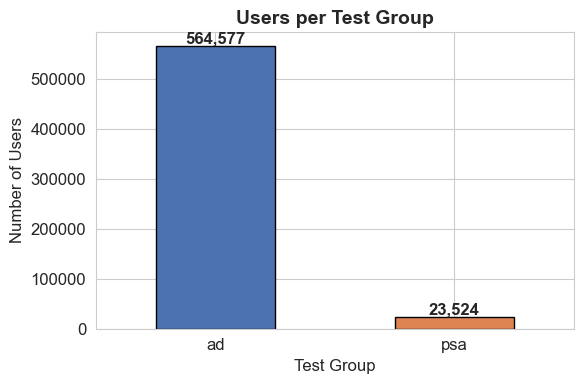

In [7]:
# Visualize group sizes
fig, ax = plt.subplots(figsize=(6, 4))
colors = ["#4C72B0", "#DD8452"]
group_counts.plot(kind="bar", color=colors, edgecolor="black", ax=ax)
ax.set_title("Users per Test Group", fontsize=14, fontweight="bold")
ax.set_xlabel("Test Group")
ax.set_ylabel("Number of Users")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Add count labels on bars
for i, (group, count) in enumerate(group_counts.items()):
    ax.text(i, count + len(df) * 0.01, f"{count:,}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

## 4. Conversion Rates by Group

This is the central metric — what percentage of users in each group actually converted?

In [8]:
# Calculate conversion rate for each group
# 'converted' is boolean — .mean() on a boolean column gives the proportion of True values.
conversion_rates = df.groupby("test group")["converted"].mean() * 100

print("CONVERSION RATES")
print("=" * 40)
for group, rate in conversion_rates.items():
    n = group_counts[group]
    conversions = df[df["test group"] == group]["converted"].sum()
    print(f"  {group.upper():>3}: {rate:.2f}%  ({conversions:,} / {n:,} users)")

diff = conversion_rates.get("ad", 0) - conversion_rates.get("psa", 0)
print(f"\n  Difference (ad − psa): {diff:+.2f} percentage points")

CONVERSION RATES
   AD: 2.55%  (14,423 / 564,577 users)
  PSA: 1.79%  (420 / 23,524 users)

  Difference (ad − psa): +0.77 percentage points


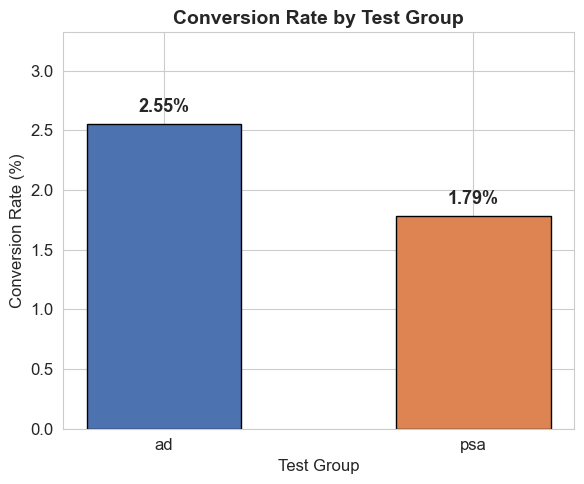

In [9]:
# Bar chart of conversion rates
fig, ax = plt.subplots(figsize=(6, 5))

bars = ax.bar(
    conversion_rates.index,
    conversion_rates.values,
    color=["#4C72B0", "#DD8452"],
    edgecolor="black",
    width=0.5,
)

ax.set_title("Conversion Rate by Test Group", fontsize=14, fontweight="bold")
ax.set_xlabel("Test Group")
ax.set_ylabel("Conversion Rate (%)")
ax.set_ylim(0, max(conversion_rates.values) * 1.3)  # Leave room for labels

# Add percentage labels on bars
for bar, rate in zip(bars, conversion_rates.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{rate:.2f}%",
        ha="center",
        fontweight="bold",
        fontsize=13,
    )

plt.tight_layout()
plt.show()

## 5. Distribution of Total Ads Shown

How many ads were users exposed to? Is the distribution skewed? Are there outliers who saw an unusually high number of ads?

In [10]:
# Summary statistics for 'total ads'
print("TOTAL ADS — SUMMARY STATISTICS")
print("=" * 40)
print(df["total ads"].describe().to_string())
print(f"\nSkewness: {df['total ads'].skew():.2f}")
print(f"Kurtosis: {df['total ads'].kurtosis():.2f}")

TOTAL ADS — SUMMARY STATISTICS
count    588101.000000
mean         24.820876
std          43.715181
min           1.000000
25%           4.000000
50%          13.000000
75%          27.000000
max        2065.000000

Skewness: 7.43
Kurtosis: 109.92


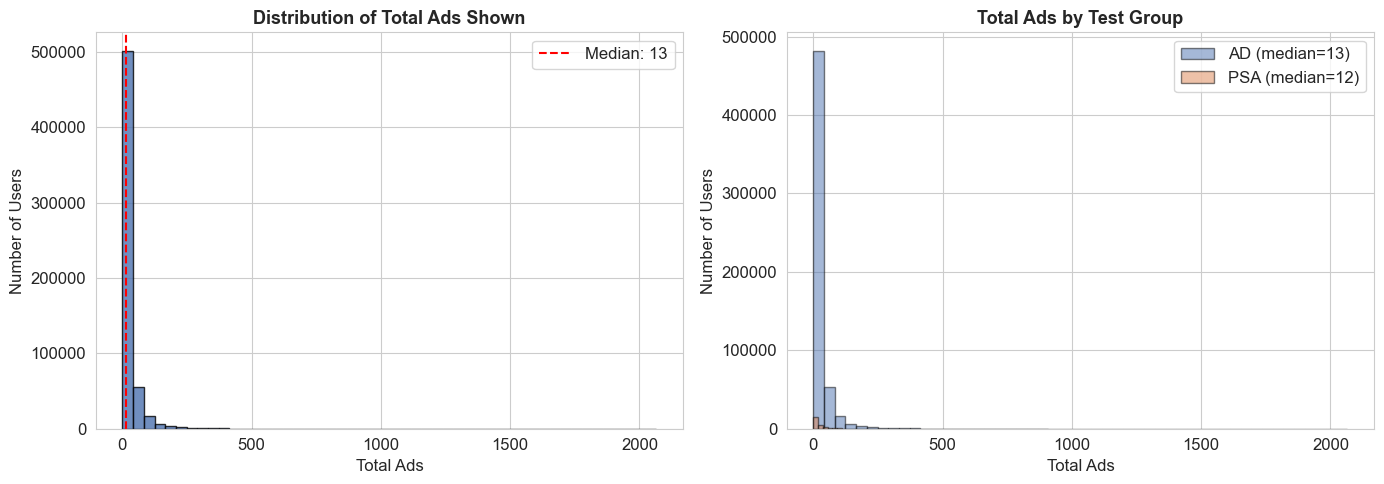

In [11]:
# Histogram of total ads — expect right-skewed distribution
# (most users see few ads, some power users see many)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Overall distribution
axes[0].hist(df["total ads"], bins=50, color="#4C72B0", edgecolor="black", alpha=0.8)
axes[0].set_title("Distribution of Total Ads Shown", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Total Ads")
axes[0].set_ylabel("Number of Users")
axes[0].axvline(df["total ads"].median(), color="red", linestyle="--", label=f'Median: {df["total ads"].median():.0f}')
axes[0].legend()

# Right: Distribution by group (are both groups exposed similarly?)
for group, color in zip(["ad", "psa"], ["#4C72B0", "#DD8452"]):
    group_data = df[df["test group"] == group]["total ads"]
    axes[1].hist(group_data, bins=50, color=color, alpha=0.5, label=f"{group.upper()} (median={group_data.median():.0f})", edgecolor="black")

axes[1].set_title("Total Ads by Test Group", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Total Ads")
axes[1].set_ylabel("Number of Users")
axes[1].legend()

plt.tight_layout()
plt.show()

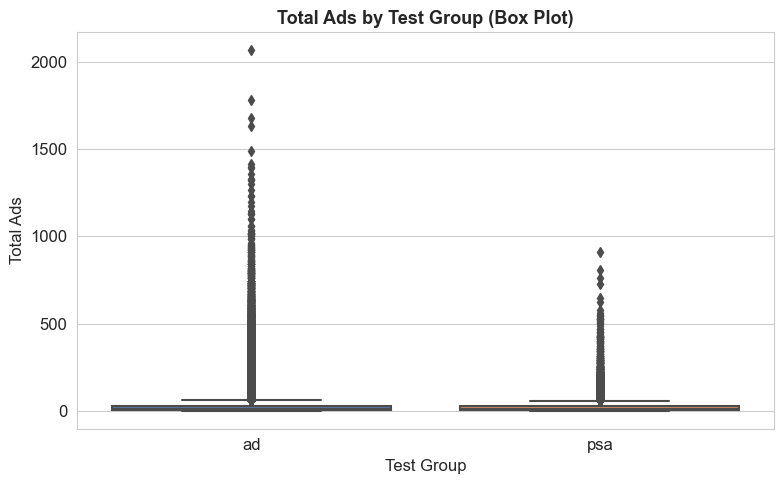

In [12]:
# Box plot to highlight outliers
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="test group", y="total ads", palette=["#4C72B0", "#DD8452"], ax=ax)
ax.set_title("Total Ads by Test Group (Box Plot)", fontsize=13, fontweight="bold")
ax.set_xlabel("Test Group")
ax.set_ylabel("Total Ads")
plt.tight_layout()
plt.show()

## 6. Most Ads Hour — Timing Patterns

At what hour of the day do users see the most ads? Are there peak hours that correlate with higher conversion?

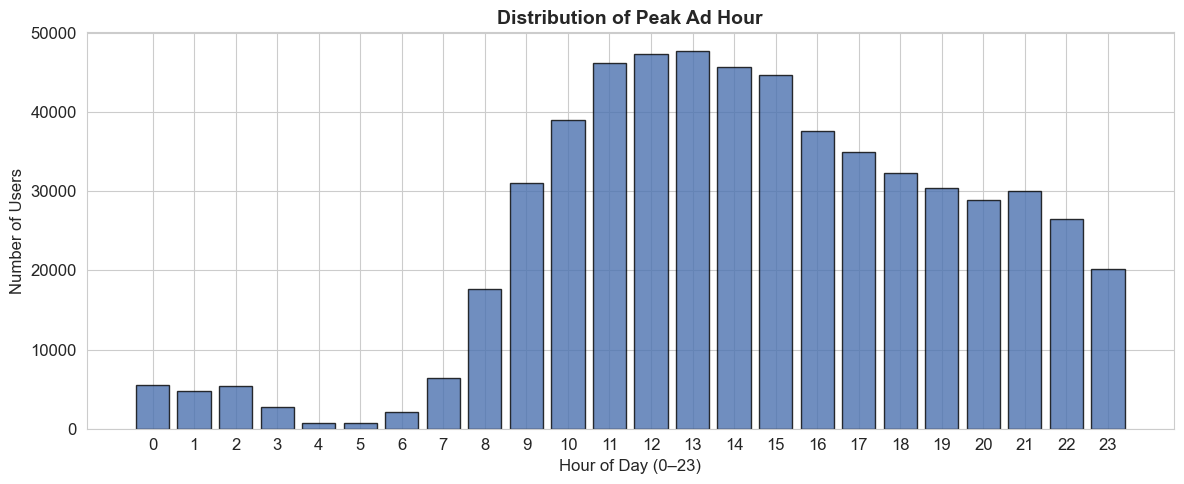

In [13]:
# Count of users by their peak ad hour
hour_counts = df["most ads hour"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(hour_counts.index, hour_counts.values, color="#4C72B0", edgecolor="black", alpha=0.8)
ax.set_title("Distribution of Peak Ad Hour", fontsize=14, fontweight="bold")
ax.set_xlabel("Hour of Day (0–23)")
ax.set_ylabel("Number of Users")
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.show()

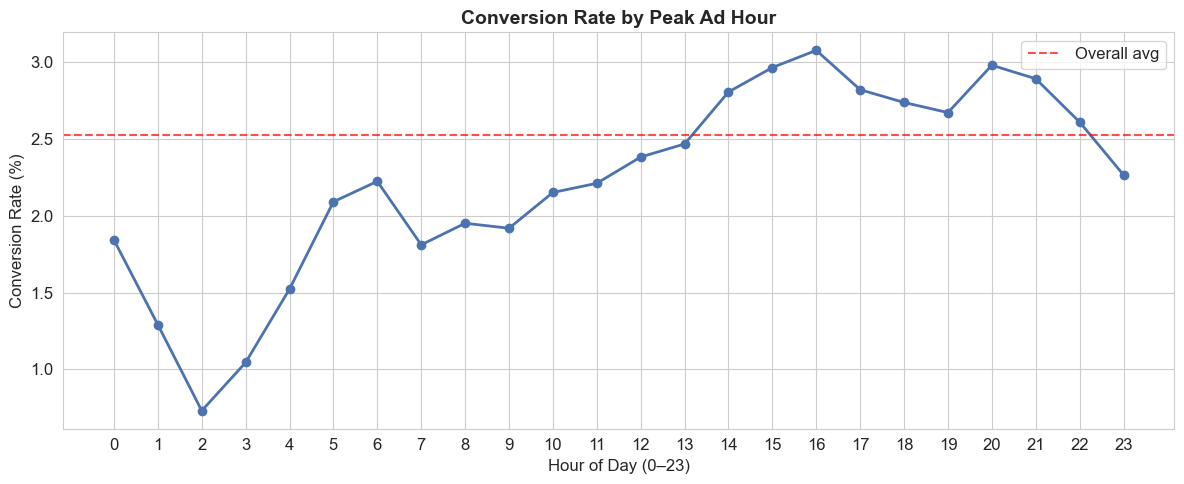

In [14]:
# Conversion rate by hour — does timing matter?
hourly_conversion = df.groupby("most ads hour")["converted"].mean() * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    hourly_conversion.index,
    hourly_conversion.values,
    marker="o",
    linewidth=2,
    color="#4C72B0",
    markersize=6,
)
ax.axhline(df["converted"].mean() * 100, color="red", linestyle="--", alpha=0.7, label="Overall avg")
ax.set_title("Conversion Rate by Peak Ad Hour", fontsize=14, fontweight="bold")
ax.set_xlabel("Hour of Day (0–23)")
ax.set_ylabel("Conversion Rate (%)")
ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout()
plt.show()

## 7. Most Ads Day — Day-of-Week Patterns

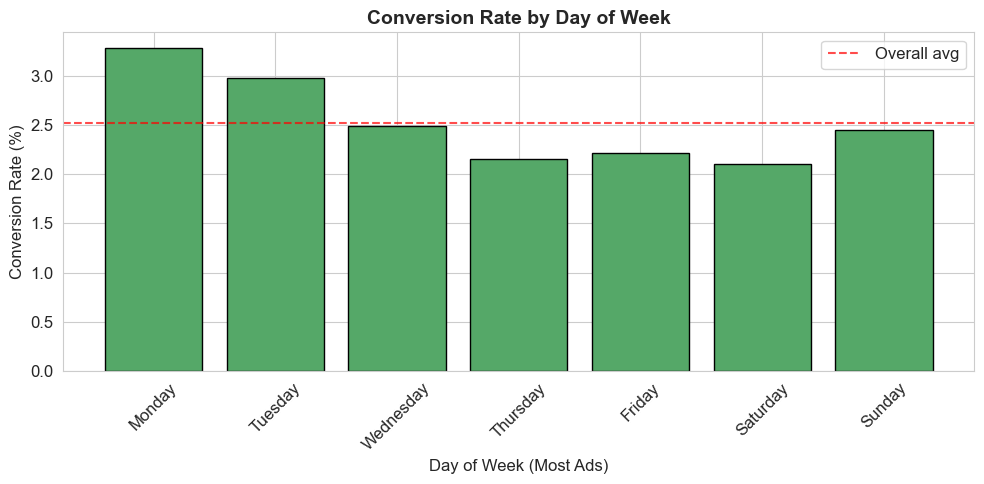

In [15]:
# Conversion rate by day of week
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Only use days that actually appear in the data
available_days = [d for d in day_order if d in df["most ads day"].unique()]

daily_conversion = (
    df.groupby("most ads day")["converted"]
    .mean()
    .reindex(available_days) * 100
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(daily_conversion.index, daily_conversion.values, color="#55A868", edgecolor="black")
ax.axhline(df["converted"].mean() * 100, color="red", linestyle="--", alpha=0.7, label="Overall avg")
ax.set_title("Conversion Rate by Day of Week", fontsize=14, fontweight="bold")
ax.set_xlabel("Day of Week (Most Ads)")
ax.set_ylabel("Conversion Rate (%)")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Key Takeaways from EDA

Before running the formal statistical test in `scripts/ab_test.py`, we can observe:

1. **Group sizes**: How balanced are the two groups?
2. **Conversion rates**: Is there a visible difference between ad and psa groups?
3. **Ad exposure**: What does the distribution of total ads look like?
4. **Timing patterns**: Do certain hours or days show higher conversion rates?

➡️ **Next step**: Run the chi-square test in `scripts/ab_test.py` to determine if the observed difference is *statistically significant* — or just random noise.

➡️ **Then**: See `notebooks/02_visualization.ipynb` for publication-quality charts with confidence intervals.